<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Import-libraries" data-toc-modified-id="Import-libraries-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Import libraries</a></span></li><li><span><a href="#Run-HypoDD" data-toc-modified-id="Run-HypoDD-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Run <code>HypoDD</code></a></span></li><li><span><a href="#Read-hypoDD.reloc-file" data-toc-modified-id="Read-hypoDD.reloc-file-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Read <code>hypoDD.reloc</code> file</a></span></li><li><span><a href="#Plot-relocated-epicenters" data-toc-modified-id="Plot-relocated-epicenters-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Plot relocated epicenters</a></span></li><li><span><a href="#Cartesian-coordinates" data-toc-modified-id="Cartesian-coordinates-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>Cartesian coordinates</a></span></li><li><span><a href="#Depth-histogram" data-toc-modified-id="Depth-histogram-6"><span class="toc-item-num">6&nbsp;&nbsp;</span>Depth histogram</a></span></li></ul></div>

In [97]:
from IPython.core.display import display, HTML 
display(HTML("<style>.container { width:100% !important; }</style>"))

/tmp/ipykernel_86402/343306588.py:1: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython display
  from IPython.core.display import display, HTML


## Import libraries

In [108]:
import numpy as np
import pandas as pd
import pygmt as pmt
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable
from glob import glob
import os
from datetime import datetime
import datetime
from numpy.random import choice
from tqdm import tqdm
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from obspy.imaging.beachball import beach

%config InlineBackend.print_figure_kwargs={'facecolor' : "w"}

# Font
import matplotlib as mpl
import matplotlib.font_manager as font_manager
font_dir = ['/home/msseo/Download/Helvetica']
for font in font_manager.findSystemFonts(font_dir):
    font_manager.fontManager.addfont(font)

mpl.rcParams['font.family']="helvetica"
mpl.rcParams['axes.unicode_minus']=False

## Run `HypoDD`

In [99]:
# Run HypoDD and arange files
os.system("./hypoDD.sh")

starting hypoDD (v1.3 - 11/2010)...          Mon Oct 20 23:22:50 2025 
INPUT FILES:
cross dtime data: dt.cc_0.7_combined
catalog dtime data: dt.ct
events: event.dat
stations: station.dat
OUTPUT FILES:
initial locations: hypoDD.loc
relocated events: hypoDD.reloc
event pair residuals: hypoDD.res
station residuals: hypoDD.sta
source parameters:  
 Relocate all clusters
 Relocate all events
Reading data ...   Mon Oct 20 23:22:50 2025 
# events =    12
# stations < maxdist =     59
# cross corr P dtimes =     559 (no OTC for      0 event pairs)
# cross corr S dtimes =     746 (no OTC for      0 event pairs)
# catalog P dtimes =     901
# catalog S dtimes =     925
# dtimes total =     3131
# events after dtime match =         12
# stations =     57
clustering ...  
Clustered events:    12
Isolated events:     0
# clusters:    1
Cluster   1:    12 events

RELOCATION OF CLUSTER: 1     Mon Oct 20 23:22:50 2025 
----------------------
Initial trial sources =     1

  IT   EV  CT  CC    RMSCT   

0

  0    0    0   0
13 13 100  95 100   45 137.1    6 -78.6   103   32  136  640 2333  640   0
14 14 100  95  96   45   0.0    2 -66.9   103    3    2    9    0  640   0
15 15 100  95  95   45  -0.1    2  -9.3   103    1    1    1    0  640   0
16 16 100  95  95   45   0.1    2  -3.0   103    1    0    1    0  640   0
17 17 100  95  91   45   0.2    1 -22.1   103    1    1    2    0  640   0
18 18 100  95  90   45   0.1    1  -7.5   103    0    0    2    0  640   0
19 19 100  95  89   45   0.1    1  -5.9   103    0    0    2    0  640   0
20 20 100  95  88   45   0.1    1  -5.8   103    0    0    2    0  640   0
21 21 100  95  82   45   0.2    1 -18.1   103    0    0    1    0  640   0
22 22 100  95  80   45   0.1    1  -7.9   103    0    0    1    0  640   0
23 23 100  95  79   45   0.1    1  -3.2   103    0    0    0    0  640   0
24 24 100  95  79   45   0.1    1  -1.0   103    0    0    0    0  640   0
25 25 100  95  71   45   0.1    1 -23.9   104    0    0    0    0  640   0
26 26 1

## Read `hypoDD.reloc` file

In [100]:
# Change hypoDD.reloc file into *csv format so that it can be read into DataFrame object
f1=open("hypoDD.reloc", 'r')
# f2=open("hypoDD.reloc.lsqr.csv", 'w')
f2=open("hypoDD.reloc.svd.csv", 'w')
lines=f1.readlines()
f2.write("ID,LAT,LON,DEPTH,X,Y,Z,EX,EY,EZ,YR,MO,DY,HR,MI,SC,MAG,NCCP,NCCS,NCTP,NCTS,RCC,RCT,CID\n")
for line in lines:
    csv_line_list=[]
    csv_line_list.append(line[0:9].replace(" ", ""))
    csv_line_list.append(line[9:20].replace(" ", ""))
    csv_line_list.append(line[20:32].replace(" ", ""))
    csv_line_list.append(line[32:42].replace(" ", ""))
    csv_line_list.append(line[42:53].replace(" ", ""))
    csv_line_list.append(line[53:64].replace(" ", ""))
    csv_line_list.append(line[64:75].replace(" ", ""))
    csv_line_list.append(line[75:84].replace(" ", ""))
    csv_line_list.append(line[84:93].replace(" ", ""))
    csv_line_list.append(line[93:102].replace(" ", ""))
    csv_line_list.append(line[102:107].replace(" ", ""))
    csv_line_list.append(line[107:110].replace(" ", ""))
    csv_line_list.append(line[110:113].replace(" ", ""))
    csv_line_list.append(line[113:116].replace(" ", ""))
    csv_line_list.append(line[116:119].replace(" ", ""))
    csv_line_list.append(line[119:126].replace(" ", ""))
    csv_line_list.append(line[126:131].replace(" ", ""))
    csv_line_list.append(line[131:137].replace(" ", ""))
    csv_line_list.append(line[137:143].replace(" ", ""))
    csv_line_list.append(line[143:149].replace(" ", ""))
    csv_line_list.append(line[149:155].replace(" ", ""))
    csv_line_list.append(line[155:162].replace(" ", ""))
    csv_line_list.append(line[162:169].replace(" ", ""))
    csv_line_list.append(line[169:173].replace(" ", ""))
    csv_line=",".join(csv_line_list)
    f2.write(csv_line+"\n")
f2.close()
f1.close()

In [101]:
path_to_dir="/home/msseo/works/19.Korea_Directivity/49.251008_Okcheon/2.HypoDD/02.dt.cc/"
svd_filename="hypoDD.reloc.svd.csv"
svd_relocated_catalog=pd.read_csv(path_to_dir+svd_filename, sep=",")
# lsqr_filename="hypoDD.reloc.lsqr.csv"
# lsqr_relocated_catalog=pd.read_csv(path_to_dir+lsqr_filename, sep=",")
# CID_list=[1, 2, 3, 4]
# relocated_catalog=relocated_catalog[relocated_catalog["CID"].isin(CID_list)].reset_index(drop=True)
svd_relocated_catalog

,ID,LAT,LON,DEPTH,X,Y,Z,EX,EY,EZ,...,MI,SC,MAG,NCCP,NCCS,NCTP,NCTS,RCC,RCT,CID
0,200000,36.284709,127.759733,7.894,-16.3,98.7,-669.1,0.4,0.4,1.7,...,32,38.86,0.0,81,100,204,186,0.001,0.042,1
1,200001,36.284802,127.759920,7.886,0.8,109.5,-677.7,0.3,0.3,1.1,...,28,9.44,0.0,123,116,242,198,0.001,0.042,1
2,200002,36.284607,127.759701,7.869,-19.2,87.6,-694.5,0.4,0.4,1.3,...,52,47.96,0.0,57,89,137,153,0.001,0.041,1
3,200003,36.284896,127.760010,7.943,8.6,119.5,-620.3,0.3,0.3,1.2,...,22,6.36,0.0,124,129,241,201,0.001,0.043,1
4,200004,36.285038,127.760173,7.955,23.0,135.3,-608.3,0.3,0.3,1.1,...,17,12.85,0.0,109,117,216,178,0.001,0.040,1
5,200005,36.284680,127.759790,7.973,-10.8,95.6,-590.3,0.4,0.4,1.4,...,49,37.30,0.0,64,80,236,201,0.001,0.061,1
6,200006,36.284709,127.759920,7.839,0.5,98.9,-724.2,0.5,0.7,1.9,...,55,39.02,0.0,24,42,53,70,0.001,0.030,1
7,200007,36.284269,127.759090,7.966,-73.8,50.3,-597.1,0.9,1.0,3.6,...,8,17.36,0.0,0,38,44,65,0.001,0.035,1
8,200008,36.284900,127.760042,7.957,11.7,120.1,-606.1,1.1,1.2,2.5,...,14,30.50,0.0,6,24,52,54,0.001,0.038,1
9,200009,36.285693,127.760352,7.990,39.8,208.3,-573.6,1.6,1.1,2.7,...,16,3.55,0.0,5,19,105,130,0.001,0.041,1


In [102]:
kma_catalog=pd.read_csv("/home/msseo/works/19.Korea_Directivity/49.251008_Okcheon/event_catalog/okcheon_catalog.csv", sep=',')
mag_list=np.array(kma_catalog["Magnitude"])

In [103]:
len(mag_list)

12

## Plot relocated epicenters

In [104]:
# Reference: https://forum.generic-mapping-tools.org/t/pygmt-plot-errorbars/1354/5

# 1) SVD relocation data
svd_df=pd.DataFrame(
    data={
        "x": svd_relocated_catalog["LON"],
        "y": svd_relocated_catalog["LAT"],
        "x-error": svd_relocated_catalog["EX"]*0.000009009,
        "y-error": svd_relocated_catalog["EY"]*0.000009009
    }
)

# # 2) LSQR relocation data
# lsqr_df=pd.DataFrame(
#     data={
#         "x": lsqr_relocated_catalog["LON"],
#         "y": lsqr_relocated_catalog["LAT"],
#         "x-error": lsqr_relocated_catalog["EX"]*0.000009009,
#         "y-error": lsqr_relocated_catalog["EY"]*0.000009009
#     }
# )

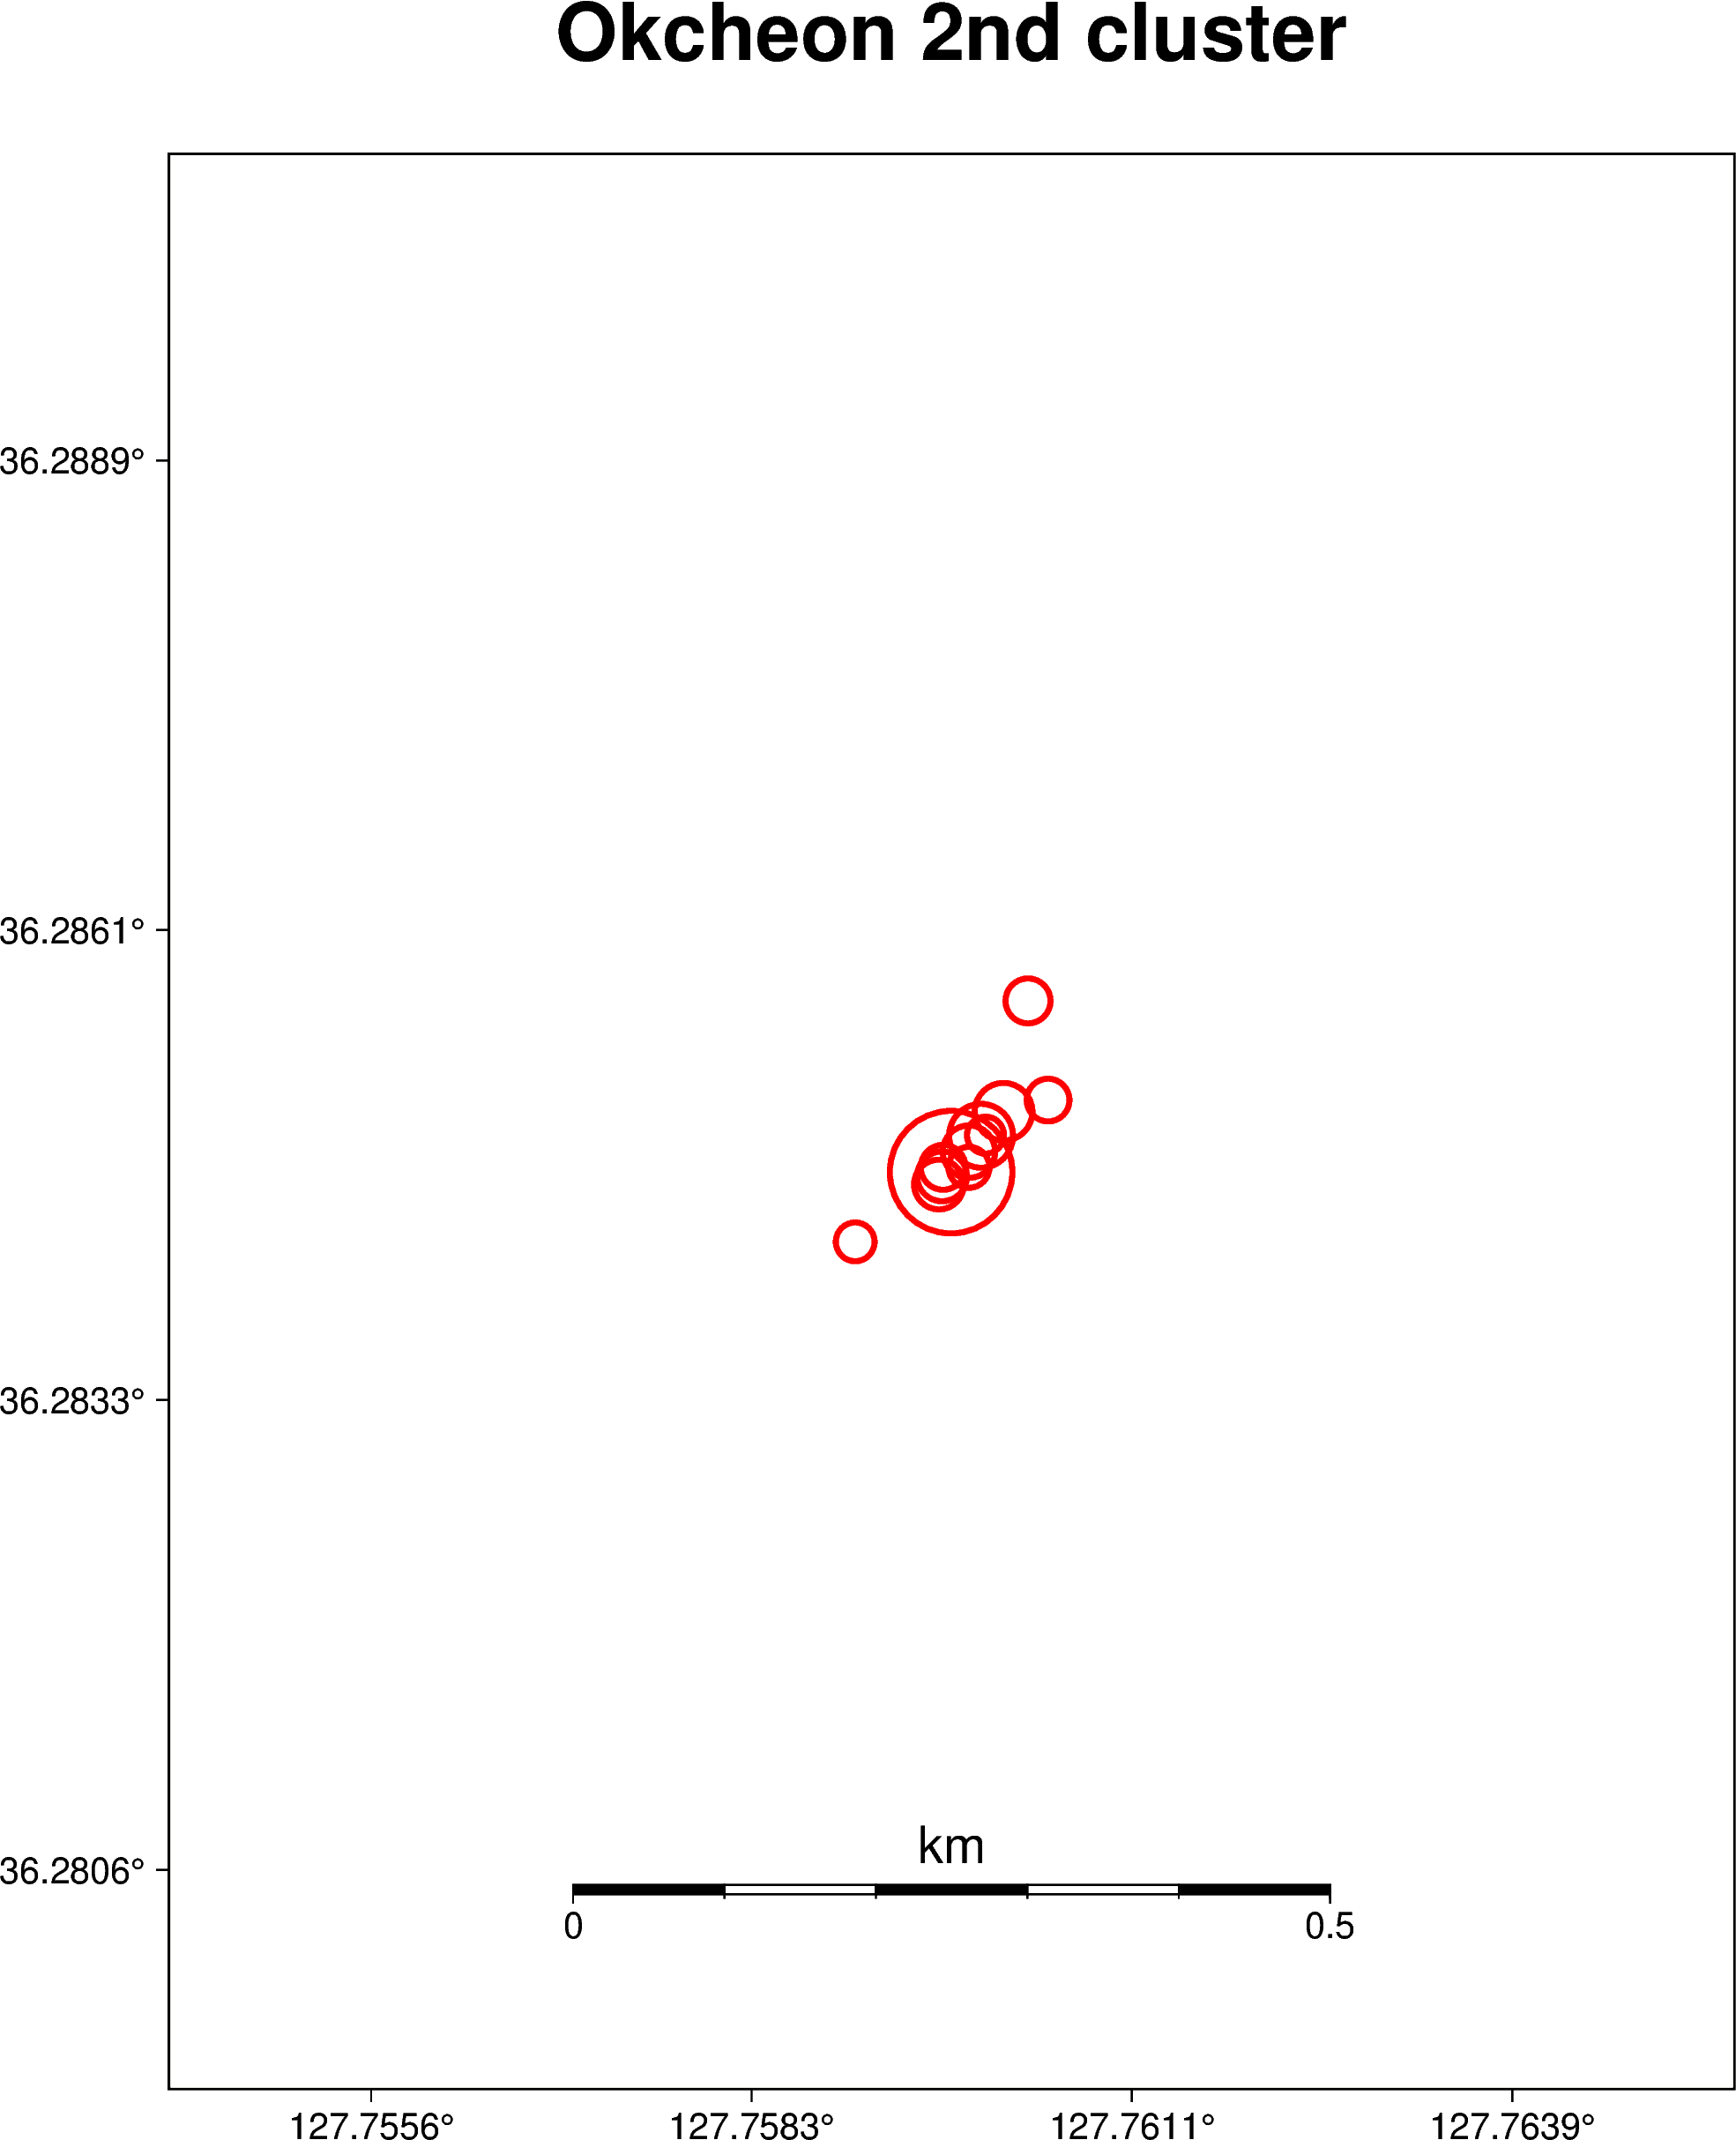

In [105]:
################ Draw epicenter locations with fault traces and stations ################
fig=pmt.Figure()
pmt.config(FORMAT_GEO_MAP="ddd.xxxx", MAP_FRAME_TYPE="plain") # Use decimal degrees for latitude/longitude

#######################################################################################################
# 1) Set the region for the plot to be slightly larger than the data bounds
region=[svd_relocated_catalog["LON"].min()-0.005,
        svd_relocated_catalog["LON"].max()+0.005,
        svd_relocated_catalog["LAT"].min()-0.005,
        svd_relocated_catalog["LAT"].max()+0.005
        ]

fig.basemap(region=region, projection="M15c", frame=["a", '+t"Okcheon 2nd cluster"'])
fig.coast(land="white", water="#fff0dc", shorelines=True, map_scale="n0.5/0.1+f+l+c126.72/35.70+w0.5")

#######################################################################################################
# 2) Plot newly located epicenters 

# Plot epicenters
for i in range(len(svd_relocated_catalog)):
    csize=0.25*np.exp(0.5*mag_list[i])
    # csize=0.5
    fig.plot(x=svd_relocated_catalog["LON"][i], y=svd_relocated_catalog["LAT"][i], style=f"c{csize}c", pen="1.5p,red")

fig.show(width=500)
# fig.savefig(dpi=300, fname="Figure/200811_cluster_10km_epicenter_map_dt_cc.png", show=False)

## Cartesian coordinates

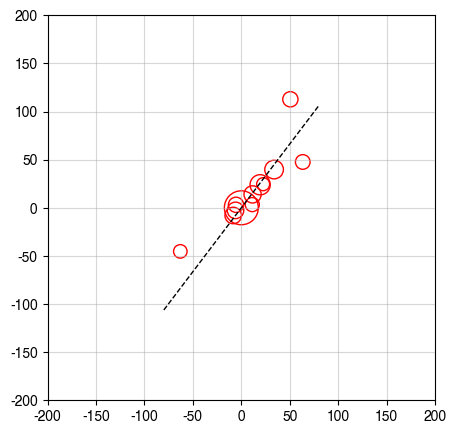

In [106]:
main_x, main_y=svd_relocated_catalog["X"][5], svd_relocated_catalog["Y"][5]

plt.figure(figsize=(5, 5))
x=np.linspace(-80, 80, 10000)
y=np.tan(np.deg2rad(90.0-37.0))*x
plt.scatter(svd_relocated_catalog["X"]-main_x, svd_relocated_catalog["Y"]-main_y, color="r", s=50*np.exp(0.8*mag_list), facecolors="none")
# plt.scatter(svd_relocated_catalog["X"]-np.mean(svd_relocated_catalog["X"]), svd_relocated_catalog["Y"]-np.mean(svd_relocated_catalog["Y"]), color="r", s=50*np.exp(0.8*mag_list), facecolors="none")
plt.plot(x, y, color="k", lw=1, linestyle="--")
plt.xlim(-200, 200)
plt.ylim(-200, 200)
plt.grid(True, alpha=0.5)
plt.show();

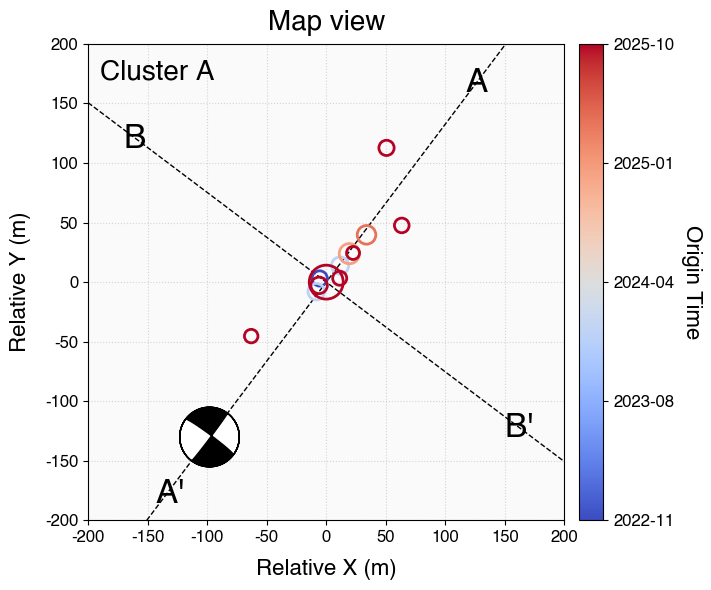

In [132]:
column_map={'YR': 'year', 'MO': 'month', 'DY': 'day', 'HR': 'hour', 'MI': 'minute'}
svd_relocated_catalog['origin_time']=pd.to_datetime(svd_relocated_catalog[['YR', 'MO', 'DY', 'HR', 'MI']].rename(columns=column_map))+pd.to_timedelta(svd_relocated_catalog['SC'], unit='s')
time_numeric=mdates.date2num(svd_relocated_catalog['origin_time'])

cmap=plt.colormaps['coolwarm']
norm=mcolors.Normalize(vmin=np.min(time_numeric), vmax=np.max(time_numeric))
rgba_colors=cmap(norm(time_numeric))

fig, ax=plt.subplots(figsize=(7, 6))

# Plot the fault line
x_line=np.linspace(-200, 200, 50)
y_line1=np.tan(np.deg2rad(90.0-37.0))*x_line
ax.plot(x_line, y_line1, color="k", lw=1, linestyle="--")
y_line2=np.tan(np.deg2rad(90.0-127.0))*x_line
ax.plot(x_line, y_line2, color="k", lw=1, linestyle="--")

scatter=ax.scatter(
    svd_relocated_catalog["X"]-main_x,
    svd_relocated_catalog["Y"]-main_y,
    s=50*np.exp(0.8 * mag_list), # Size by magnitude
    facecolors="none",           # Keep interior empty (transparent)
    edgecolors=rgba_colors,      # Color edges by numerical origin time
    linewidth=2.0,               # Make edges more visible
    zorder=10
)

focmec=[37.0, 87.2, -173.3]
# focmec=[293., 70., -15.]
fm=beach(focmec, width=50, linewidth=1.0, xy=(-98, -130), facecolor='black', zorder=20)
ax.add_collection(fm)

# Add the colorbar, linked to the scatter plot
sm=cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([]) # You can safely ignore this line. It's needed for the colorbar to work.

divider=make_axes_locatable(ax)
cax=divider.append_axes("right", size="5%", pad=0.15)
cbar=fig.colorbar(sm, cax=cax) # Draw colorbar on the new axis
cbar.set_label("Origin Time", fontsize=16, rotation=270, labelpad=20)

# Format the colorbar ticks to show readable dates
tick_locs=np.linspace(time_numeric.min(), time_numeric.max(), 5) # Choose 5 ticks
cbar.set_ticks(tick_locs)
tick_labels=[mdates.num2date(loc).strftime('%Y-%m') for loc in tick_locs]
cbar.set_ticklabels(tick_labels)
cbar.ax.tick_params(labelsize=12)

ax.text(x=-170, y=113, s="B", fontsize=24, color="k")
ax.text(x=150, y=-130, s="B'", fontsize=24, color="k")
ax.text(x=117, y=160, s="A", fontsize=24, color="k")
ax.text(x=-143, y=-185, s="A'", fontsize=24, color="k")
ax.text(x=-190, y=170, s="Cluster A", fontsize=20, color="k")

# Final plot formatting
ax.set_xlim(-200, 200)
ax.set_ylim(-200, 200)
ax.set_aspect('equal', adjustable='box') # Crucial for distortion-free spatial plots
ax.grid(True, alpha=0.5, linestyle=':')
ax.set_title("Map view", fontsize=20, pad=10)
ax.set_xlabel("Relative X (m)", fontsize=16, labelpad=10)
ax.set_ylabel("Relative Y (m)", fontsize=16, labelpad=10)
ax.tick_params(axis='both', which='major', labelsize=12)
ax.set_facecolor('#FAFAFA') 

plt.tight_layout()
plt.show();

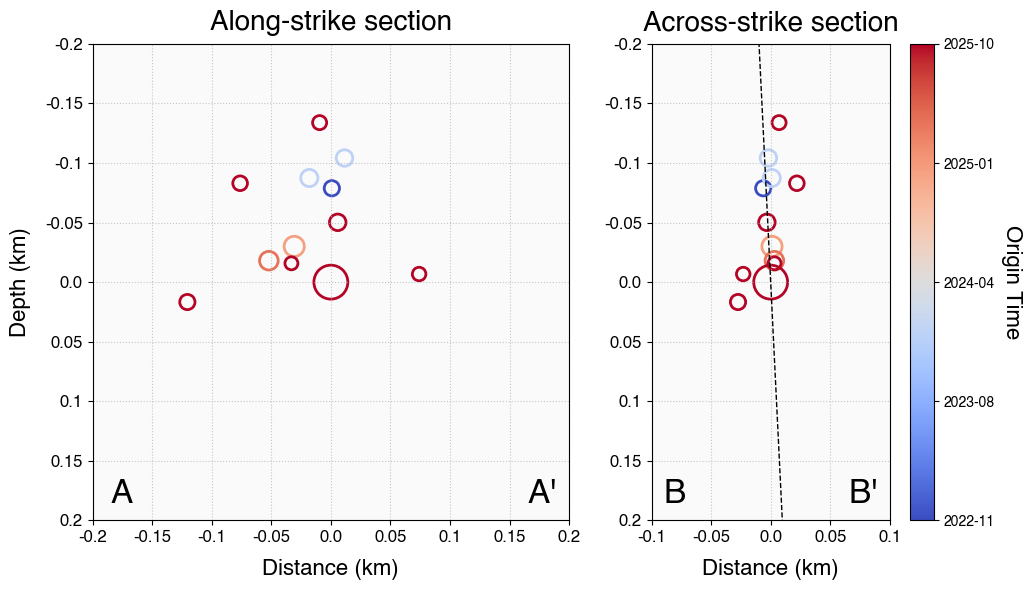

In [143]:
main_x = svd_relocated_catalog['X'].iloc[5]
main_y = svd_relocated_catalog['Y'].iloc[5]
main_z = svd_relocated_catalog['Z'].iloc[5]

column_map={'YR': 'year', 'MO': 'month', 'DY': 'day', 'HR': 'hour', 'MI': 'minute'}
svd_relocated_catalog['origin_time']=pd.to_datetime(svd_relocated_catalog[['YR', 'MO', 'DY', 'HR', 'MI']].rename(columns=column_map))+pd.to_timedelta(svd_relocated_catalog['SC'], unit='s')
time_numeric=mdates.date2num(svd_relocated_catalog['origin_time'])

cmap=plt.colormaps['coolwarm']
norm=mcolors.Normalize(vmin=np.min(time_numeric), vmax=np.max(time_numeric))
rgba_colors=cmap(norm(time_numeric))

# Define strike angle and calculate rotation angle in radians
strike_angle_from_north=37.0  # degrees clockwise from North
theta_rad=np.deg2rad(90.0-strike_angle_from_north) # Math angle CCW from East

# Calculate relative hypocenter coordinates
rel_x=svd_relocated_catalog['X']-main_x
rel_y=svd_relocated_catalog['Y']-main_y
rel_depth=-(svd_relocated_catalog['Z'] - main_z)/1000.0 # Convert to km

# Apply rotation formulas
svd_relocated_catalog['dist_along_strike']=rel_x*np.cos(theta_rad)+rel_y*np.sin(theta_rad)
svd_relocated_catalog['dist_across_strike']=-rel_x*np.sin(theta_rad)+rel_y*np.cos(theta_rad)

# Convert distances to km for plotting
svd_relocated_catalog['dist_along_strike'] /= 1000.0
svd_relocated_catalog['dist_across_strike'] /= 1000.0

# --- 2. Create Depth Section Plots ---
fig, axes=plt.subplots(1, 2, figsize=(12, 6))

# Plot 1: Along-strike depth section
ax1=axes[0]
ax1.scatter(
    svd_relocated_catalog['dist_along_strike'],
    rel_depth,
    s=50*np.exp(0.8 * mag_list),
    facecolors="none",
    edgecolors=rgba_colors,
    linewidth=2.0
)
ax1.set_title("Along-strike section", fontsize=20, pad=10)
ax1.set_xlabel("Distance (km)", fontsize=16, labelpad=10)
ax1.set_ylabel("Depth (km)", fontsize=16, labelpad=10)
ax1.set_xlim(-0.2, 0.2)
ax1.set_ylim(-0.2, 0.2)
ax1.set_xticks(np.arange(-0.2, 0.25, 0.05))
ax1.set_xticklabels(np.round(np.arange(0.2, -0.25, -0.05), 2))
ax1.set_yticks(np.arange(-0.2, 0.25, 0.05))
ax1.set_yticklabels(np.round(np.arange(0.2, -0.25, -0.05), 2))
ax1.invert_xaxis()
ax1.set_aspect('equal', adjustable='box')
ax1.grid(True, linestyle=':', alpha=0.7)
ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.set_facecolor('#FAFAFA') 
ax1.text(x=-0.165, y=-0.185, s="A'", fontsize=24, color="k")
ax1.text(x=0.185, y=-0.185, s="A", fontsize=24, color="k")

# Plot 2: Across-strike depth section
ax2=axes[1]

# Plot the fault line
x_line=np.linspace(-200, 200, 1000)
y_line=np.tan(np.deg2rad(87.2))*x_line
ax2.plot(x_line, y_line, color="k", lw=1, linestyle="--")

ax2.scatter(
    svd_relocated_catalog['dist_across_strike'],
    rel_depth,
    s=50*np.exp(0.8 * mag_list),
    facecolors="none",
    edgecolors=rgba_colors,
    linewidth=2.0
)
ax2.set_title("Across-strike section", fontsize=20, pad=10)
ax2.set_xlabel("Distance (km)", fontsize=16, labelpad=10)
# ax2.set_ylabel("Depth (km)", fontsize=12)
ax2.set_xlim(-0.1, 0.1)
ax2.set_ylim(-0.2, 0.2)
ax2.set_xticks(np.arange(-0.1, 0.15, 0.05))
ax2.set_xticklabels(np.round(np.arange(0.1, -0.15, -0.05), 2))
ax2.set_yticks(np.arange(-0.2, 0.25, 0.05))
ax2.set_yticklabels(np.round(np.arange(0.2, -0.25, -0.05), 2))
ax2.invert_xaxis()
ax2.set_aspect('equal', adjustable='box')
ax2.grid(True, linestyle=':', alpha=0.7)
ax2.tick_params(axis='both', which='major', labelsize=12)
ax2.set_facecolor('#FAFAFA')
ax2.text(x=-0.065, y=-0.185, s="B'", fontsize=24, color="k")
ax2.text(x=0.09, y=-0.185, s="B", fontsize=24, color="k")

# --- 3. Add a Single Colorbar to the Rightmost Side ---
# Create a ScalarMappable object for the colorbar
sm=cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Use make_axes_locatable on the rightmost plot (ax2) to create space for the colorbar
divider=make_axes_locatable(ax2)
cax=divider.append_axes("right", size="10%", pad=0.2) # You can adjust pad
cbar=fig.colorbar(sm, cax=cax) # Draw the colorbar on this new axis

# Format the colorbar
cbar.set_label("Origin Time", fontsize=16, rotation=270, labelpad=20)
tick_locs=np.linspace(time_numeric.min(), time_numeric.max(), 5)
cbar.set_ticks(tick_locs)
tick_labels=[mdates.num2date(loc).strftime('%Y-%m') for loc in tick_locs]
cbar.set_ticklabels(tick_labels)
plt.subplots_adjust(wspace=-0.65)

# Use tight_layout to automatically adjust subplot params so that subplots are nicely fit in the figure.
fig.tight_layout()
plt.show();

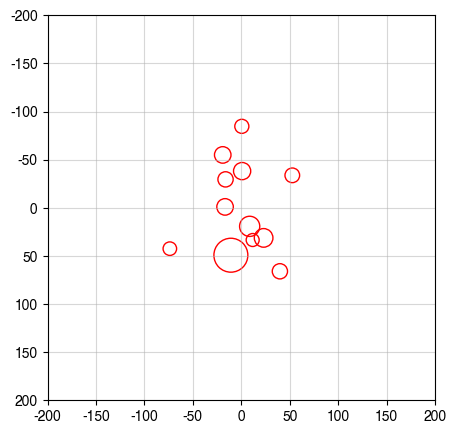

In [11]:
plt.figure(figsize=(5, 5))
plt.scatter(svd_relocated_catalog["X"]-np.mean(svd_relocated_catalog["X"]), svd_relocated_catalog["Z"]-np.mean(svd_relocated_catalog["Z"]), color="r", s=50*np.exp(0.8*mag_list), facecolors="none")
plt.xlim(-200, 200)
plt.ylim(200, -200)
plt.grid(True, alpha=0.5)
plt.show();

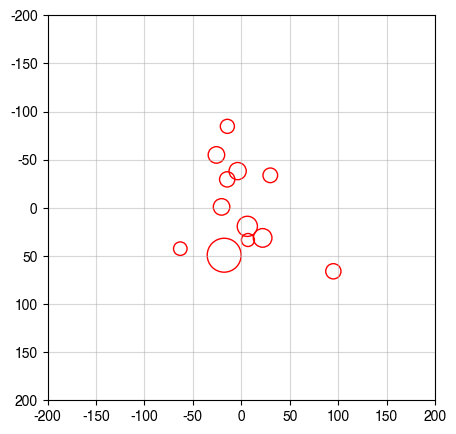

In [12]:
plt.figure(figsize=(5, 5))
plt.scatter(svd_relocated_catalog["Y"]-np.mean(svd_relocated_catalog["Y"]), svd_relocated_catalog["Z"]-np.mean(svd_relocated_catalog["Z"]), color="r", s=50*np.exp(0.8*mag_list), facecolors="none")
plt.xlim(-200, 200)
plt.ylim(200, -200)
plt.grid(True, alpha=0.5)
plt.show();

## Depth histogram

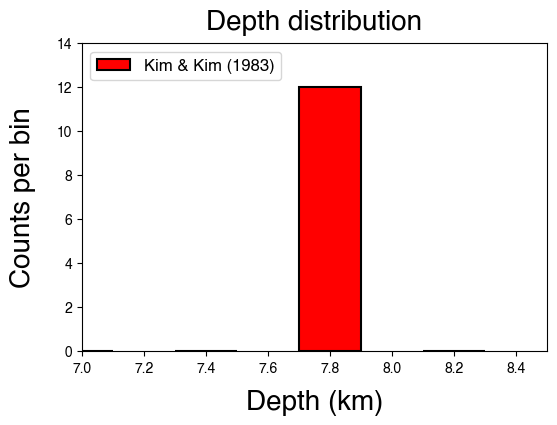

In [13]:
data=svd_relocated_catalog["DEPTH"]
plt.figure(figsize=(6, 4))
plt.hist(data, bins=50, rwidth=0.5, color="r", edgecolor="k", lw=1.5, range=(0, 20), label="Kim & Kim (1983)")
plt.title("Depth distribution", fontsize=20, pad=10)
plt.xlabel("Depth (km)", fontsize=20, labelpad=10)
plt.ylabel("Counts per bin", fontsize=20, labelpad=15)
# plt.xticks(np.arange(0, 18, 2), fontsize=18)
# plt.yticks(np.arange(0, 18, 2), fontsize=18)
# plt.xticks(np.arange(0, 22, 2), fontsize=15)
# plt.yticks(np.arange(0, 55, 5), fontsize=15)
plt.legend(prop={"size": 12}, loc="upper left")
plt.xlim(7, 8.5)
plt.ylim(0, 14)
# plt.ylim(7, 9)
plt.show()
# plt.savefig("Figure/dt_cc_depth_distribution.png", dpi=300)